In [ ]:
import torch

print("====================================")
print("DAY 4 SYSTEM CHECK")
print("====================================")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU NOT AVAILABLE")

DAY 4 SYSTEM CHECK
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("====================================")
print("GOOGLE DRIVE CHECK")
print("====================================")

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

import os

print("Project exists:", os.path.exists(PROJECT_ROOT))

if os.path.exists(PROJECT_ROOT):
    print("Project contents:")
    print(os.listdir(PROJECT_ROOT))

Mounted at /content/drive
GOOGLE DRIVE CHECK
Project exists: True
Project contents:
['data', 'models', 'results', 'logs', 'notebooks', 'figures']


In [ ]:
import os

print("====================================")
print("EXISTING RESULTS CHECK")
print("====================================")

files_to_check = [
    "results/baseline_results.json",
    "results/kd_results.json",
    "results/baseline_training_history.json",
    "results/kd_training_history.json",
    "results/master_results.csv",
    "models/baseline_student/final",
    "models/kd/student_epoch3"
]

for item in files_to_check:
    path = os.path.join(PROJECT_ROOT, item)
    print(f"{item}: {os.path.exists(path)}")

EXISTING RESULTS CHECK
results/baseline_results.json: True
results/kd_results.json: True
results/baseline_training_history.json: True
results/kd_training_history.json: True
results/master_results.csv: True
models/baseline_student/final: True
models/kd/student_epoch3: True


In [ ]:
import os
import random
import numpy as np
import torch

SEED = 43

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("====================================")
print("SEED 43 — BASELINE STUDENT")
print("====================================")

print("Seed:", SEED)
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
print("Student:", "google/bert_uncased_L-2_H-128_A-2")
print("Dataset:", "SST-2")
print("Epochs:", 3)
print("Batch size:", 16)
print("Learning rate:", 2e-5)

SEED 43 — BASELINE STUDENT
Seed: 43
Device: cuda
Student: google/bert_uncased_L-2_H-128_A-2
Dataset: SST-2
Epochs: 3
Batch size: 16
Learning rate: 2e-05


In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)
from torch.utils.data import DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
import torch
import time
import json
import os

# ==============================
# CONFIG
# ==============================

SEED = 43
STUDENT_MODEL = "google/bert_uncased_L-2_H-128_A-2"
MAX_LENGTH = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reproducibility
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ==============================
# LOAD DATASET
# ==============================

print("Loading SST-2...")

dataset = load_dataset("nyu-mll/glue", "sst2")

print("Train:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))

# ==============================
# TOKENIZER
# ==============================

tokenizer = AutoTokenizer.from_pretrained(STUDENT_MODEL)

def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized = dataset.map(
    tokenize_function,
    batched=True
)

# Rename label column for model
tokenized = tokenized.rename_column("label", "labels")

# Keep only required columns
tokenized.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

# ==============================
# DATALOADER
# ==============================

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

train_loader = DataLoader(
    tokenized["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

val_loader = DataLoader(
    tokenized["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ==============================
# MODEL
# ==============================

print("\nLoading fresh baseline student...")

model = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_MODEL,
    num_labels=2
)

model.to(DEVICE)

print("Model device:", next(model.parameters()).device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

# ==============================
# OPTIMIZER
# ==============================

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# ==============================
# VALIDATION FUNCTION
# ==============================

def evaluate(model, loader):
    model.eval()

    losses = []
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            outputs = model(**batch)

            losses.append(outputs.loss.item())

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch["labels"].cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return (
        sum(losses) / len(losses),
        accuracy,
        f1
    )

# ==============================
# TRAINING
# ==============================

history = []

print("\n====================================")
print("STARTING SEED 43 BASELINE TRAINING")
print("====================================")

for epoch in range(1, EPOCHS + 1):

    model.train()

    epoch_start = time.time()

    total_train_loss = 0.0

    for step, batch in enumerate(train_loader, start=1):

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(**batch)

        loss = outputs.loss

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

        if step % 500 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    avg_train_loss = (
        total_train_loss / len(train_loader)
    )

    val_loss, val_accuracy, val_f1 = evaluate(
        model,
        val_loader
    )

    epoch_time = time.time() - epoch_start

    epoch_result = {
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_f1": val_f1,
        "time_seconds": epoch_time
    }

    history.append(epoch_result)

    print("\n------------------------------------")
    print(f"Epoch {epoch} complete")
    print(f"Train loss: {avg_train_loss:.4f}")
    print(f"Val loss: {val_loss:.4f}")
    print(f"Val accuracy: {val_accuracy:.4f}")
    print(f"Val F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.2f} sec")
    print("------------------------------------")

# ==============================
# SAVE SEED 43 CHECKPOINT
# ==============================

checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "baseline_student_seed43"
)

os.makedirs(
    checkpoint_path,
    exist_ok=True
)

model.save_pretrained(checkpoint_path)
tokenizer.save_pretrained(checkpoint_path)

# ==============================
# SAVE RESULTS
# ==============================

final_result = {
    "experiment": "E1_baseline_student_seed43",
    "student_model": STUDENT_MODEL,
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "seed": SEED,
    "total_parameters": sum(
        p.numel() for p in model.parameters()
    ),
    "validation_loss": history[-1]["validation_loss"],
    "validation_accuracy": history[-1]["validation_accuracy"],
    "validation_f1": history[-1]["validation_f1"]
}

results_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_seed43_results.json"
)

history_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_seed43_training_history.json"
)

with open(results_path, "w") as f:
    json.dump(final_result, f, indent=4)

with open(history_path, "w") as f:
    json.dump(history, f, indent=4)

print("\n====================================")
print("SEED 43 BASELINE COMPLETE")
print("====================================")
print("Accuracy:", final_result["validation_accuracy"])
print("F1:", final_result["validation_f1"])
print("Checkpoint:", checkpoint_path)
print("Results saved:", results_path)

Loading SST-2...


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

...

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model device: cuda:0
Parameters: 4386178

STARTING SEED 43 BASELINE TRAINING
Epoch 1/3 | Step 500/4210 | Loss 0.5200
Epoch 1/3 | Step 1000/4210 | Loss 0.5881
Epoch 1/3 | Step 1500/4210 | Loss 0.6346
Epoch 1/3 | Step 2000/4210 | Loss 0.3544
Epoch 1/3 | Step 2500/4210 | Loss 0.2355
Epoch 1/3 | Step 3000/4210 | Loss 0.3402
Epoch 1/3 | Step 3500/4210 | Loss 0.4285
Epoch 1/3 | Step 4000/4210 | Loss 0.2538

------------------------------------
Epoch 1 complete
Train loss: 0.4395
Val loss: 0.4477
Val accuracy: 0.7947
Val F1: 0.8004
Time: 60.57 sec
------------------------------------
Epoch 2/3 | Step 500/4210 | Loss 0.1209
Epoch 2/3 | Step 1000/4210 | Loss 0.2984
Epoch 2/3 | Step 1500/4210 | Loss 0.1189
Epoch 2/3 | Step 2000/4210 | Loss 0.3268
Epoch 2/3 | Step 2500/4210 | Loss 0.2691
Epoch 2/3 | Step 3000/4210 | Loss 0.2001
Epoch 2/3 | Step 3500/4210 | Loss 0.1222
Epoch 2/3 | Step 4000/4210 | Loss 0.1161

------------------------------------
Epoch 2 complete
Train loss: 0.3112
Val loss: 0.446

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


SEED 43 BASELINE COMPLETE
Accuracy: 0.819954128440367
F1: 0.8291621327529923
Checkpoint: /content/drive/MyDrive/SLM_KD_Research/models/baseline_student_seed43
Results saved: /content/drive/MyDrive/SLM_KD_Research/results/baseline_seed43_results.json


In [ ]:
# ============================================
# DAY 4 — SEED 43 KD STUDENT
# ============================================

import os
import json
import time
import random
import numpy as np
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

# ============================================
# CONFIG
# ============================================

SEED = 43

TEACHER_MODEL = "textattack/bert-base-uncased-SST-2"
STUDENT_MODEL = "google/bert_uncased_L-2_H-128_A-2"

MAX_LENGTH = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3

TEMPERATURE = 2.0
ALPHA = 0.5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================
# SEED
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("====================================")
print("SEED 43 — KD STUDENT")
print("====================================")
print("Teacher:", TEACHER_MODEL)
print("Student:", STUDENT_MODEL)
print("Temperature:", TEMPERATURE)
print("Alpha:", ALPHA)
print("Device:", DEVICE)

# ============================================
# LOAD SST-2
# ============================================

dataset = load_dataset(
    "nyu-mll/glue",
    "sst2"
)

print("\nDataset:")
print("Train:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))

# ============================================
# LOAD TOKENIZERS
# ============================================

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_MODEL
)

teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_MODEL
)

# ============================================
# KD DATASET
# ============================================

class KDDataset(Dataset):

    def __init__(
        self,
        dataset_split,
        student_tokenizer,
        teacher_tokenizer
    ):

        self.data = dataset_split
        self.student_tokenizer = student_tokenizer
        self.teacher_tokenizer = teacher_tokenizer

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        item = self.data[idx]

        sentence = item["sentence"]
        label = item["label"]

        student_encoding = self.student_tokenizer(
            sentence,
            truncation=True,
            max_length=MAX_LENGTH
        )

        teacher_encoding = self.teacher_tokenizer(
            sentence,
            truncation=True,
            max_length=MAX_LENGTH
        )

        return {
            "student_input_ids":
                student_encoding["input_ids"],

            "student_attention_mask":
                student_encoding["attention_mask"],

            "teacher_input_ids":
                teacher_encoding["input_ids"],

            "teacher_attention_mask":
                teacher_encoding["attention_mask"],

            "labels": label
        }

# ============================================
# COLLATOR
# ============================================

def kd_collate(batch):

    student_batch = student_tokenizer.pad(
        {
            "input_ids":
                [x["student_input_ids"] for x in batch],
            "attention_mask":
                [x["student_attention_mask"] for x in batch]
        },
        padding=True,
        return_tensors="pt"
    )

    teacher_batch = teacher_tokenizer.pad(
        {
            "input_ids":
                [x["teacher_input_ids"] for x in batch],
            "attention_mask":
                [x["teacher_attention_mask"] for x in batch]
        },
        padding=True,
        return_tensors="pt"
    )

    labels = torch.tensor(
        [x["labels"] for x in batch],
        dtype=torch.long
    )

    return {
        "student_input_ids":
            student_batch["input_ids"],

        "student_attention_mask":
            student_batch["attention_mask"],

        "teacher_input_ids":
            teacher_batch["input_ids"],

        "teacher_attention_mask":
            teacher_batch["attention_mask"],

        "labels": labels
    }

# ============================================
# DATALOADERS
# ============================================

train_dataset = KDDataset(
    dataset["train"],
    student_tokenizer,
    teacher_tokenizer
)

val_dataset = KDDataset(
    dataset["validation"],
    student_tokenizer,
    teacher_tokenizer
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=kd_collate
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=kd_collate
)

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ============================================
# LOAD TEACHER
# ============================================

print("\nLoading teacher...")

teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_MODEL,
    num_labels=2
)

teacher.to(DEVICE)

teacher.eval()

for param in teacher.parameters():
    param.requires_grad = False

print(
    "Teacher parameters:",
    sum(p.numel() for p in teacher.parameters())
)

# ============================================
# LOAD FRESH STUDENT
# ============================================

print("\nLoading fresh KD student...")

student = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_MODEL,
    num_labels=2
)

student.to(DEVICE)

print(
    "Student parameters:",
    sum(p.numel() for p in student.parameters())
)

# ============================================
# OPTIMIZER
# ============================================

optimizer = AdamW(
    student.parameters(),
    lr=LEARNING_RATE
)

# ============================================
# KD LOSS
# ============================================

def calculate_kd_loss(
    student_logits,
    teacher_logits,
    labels,
    temperature,
    alpha
):

    student_log_probs = F.log_softmax(
        student_logits / temperature,
        dim=-1
    )

    teacher_probs = F.softmax(
        teacher_logits / temperature,
        dim=-1
    )

    kd_loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean"
    )

    kd_loss = kd_loss * (temperature ** 2)

    ce_loss = F.cross_entropy(
        student_logits,
        labels
    )

    total_loss = (
        alpha * kd_loss
        + (1 - alpha) * ce_loss
    )

    return total_loss, ce_loss, kd_loss

# ============================================
# VALIDATION
# ============================================

def evaluate_kd_student(model, loader):

    model.eval()

    losses = []
    predictions = []
    labels_all = []

    with torch.no_grad():

        for batch in loader:

            student_input_ids = (
                batch["student_input_ids"].to(DEVICE)
            )

            student_attention_mask = (
                batch["student_attention_mask"].to(DEVICE)
            )

            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=student_input_ids,
                attention_mask=student_attention_mask,
                labels=labels
            )

            losses.append(
                outputs.loss.item()
            )

            preds = torch.argmax(
                outputs.logits,
                dim=-1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        labels_all,
        predictions
    )

    f1 = f1_score(
        labels_all,
        predictions
    )

    return (
        sum(losses) / len(losses),
        accuracy,
        f1
    )

# ============================================
# TRAINING
# ============================================

history = []

print("\n====================================")
print("STARTING SEED 43 KD TRAINING")
print("====================================")

for epoch in range(1, EPOCHS + 1):

    student.train()

    epoch_start = time.time()

    total_loss_sum = 0.0
    ce_loss_sum = 0.0
    kd_loss_sum = 0.0

    for step, batch in enumerate(
        train_loader,
        start=1
    ):

        student_input_ids = (
            batch["student_input_ids"].to(DEVICE)
        )

        student_attention_mask = (
            batch["student_attention_mask"].to(DEVICE)
        )

        teacher_input_ids = (
            batch["teacher_input_ids"].to(DEVICE)
        )

        teacher_attention_mask = (
            batch["teacher_attention_mask"].to(DEVICE)
        )

        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()

        # Teacher forward pass
        with torch.no_grad():

            teacher_outputs = teacher(
                input_ids=teacher_input_ids,
                attention_mask=teacher_attention_mask
            )

        # Student forward pass

        student_outputs = student(
            input_ids=student_input_ids,
            attention_mask=student_attention_mask
        )

        total_loss, ce_loss, kd_loss = calculate_kd_loss(
            student_outputs.logits,
            teacher_outputs.logits,
            labels,
            TEMPERATURE,
            ALPHA
        )

        total_loss.backward()

        optimizer.step()

        total_loss_sum += total_loss.item()
        ce_loss_sum += ce_loss.item()
        kd_loss_sum += kd_loss.item()

        if step % 500 == 0:

            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Total {total_loss.item():.4f}"
            )

    avg_total_loss = (
        total_loss_sum / len(train_loader)
    )

    avg_ce_loss = (
        ce_loss_sum / len(train_loader)
    )

    avg_kd_loss = (
        kd_loss_sum / len(train_loader)
    )

    val_loss, val_accuracy, val_f1 = (
        evaluate_kd_student(
            student,
            val_loader
        )
    )

    epoch_time = time.time() - epoch_start

    result = {
        "epoch": epoch,
        "total_loss": avg_total_loss,
        "ce_loss": avg_ce_loss,
        "kd_loss": avg_kd_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_f1": val_f1,
        "time_seconds": epoch_time
    }

    history.append(result)

    print("\n------------------------------------")
    print(f"Epoch {epoch} complete")
    print(f"Total loss: {avg_total_loss:.4f}")
    print(f"CE loss: {avg_ce_loss:.4f}")
    print(f"KD loss: {avg_kd_loss:.4f}")
    print(f"Val loss: {val_loss:.4f}")
    print(f"Val accuracy: {val_accuracy:.4f}")
    print(f"Val F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.2f} sec")
    print("------------------------------------")

# ============================================
# SAVE CHECKPOINT
# ============================================

checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "kd",
    "student_seed43_epoch3"
)

os.makedirs(
    checkpoint_path,
    exist_ok=True
)

student.save_pretrained(
    checkpoint_path
)

student_tokenizer.save_pretrained(
    checkpoint_path
)

# ============================================
# SAVE RESULTS
# ============================================

final_result = {
    "experiment": "E2_KD_student_seed43",
    "teacher_model": TEACHER_MODEL,
    "student_model": STUDENT_MODEL,
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "temperature": TEMPERATURE,
    "alpha": ALPHA,
    "seed": SEED,
    "total_parameters": sum(
        p.numel() for p in student.parameters()
    ),
    "validation_loss": history[-1]["validation_loss"],
    "validation_accuracy": history[-1]["validation_accuracy"],
    "validation_f1": history[-1]["validation_f1"]
}

results_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "kd_seed43_results.json"
)

history_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "kd_seed43_training_history.json"
)

with open(results_path, "w") as f:
    json.dump(
        final_result,
        f,
        indent=4
    )

with open(history_path, "w") as f:
    json.dump(
        history,
        f,
        indent=4
    )

print("\n====================================")
print("SEED 43 KD COMPLETE")
print("====================================")
print(
    "Accuracy:",
    final_result["validation_accuracy"]
)
print(
    "F1:",
    final_result["validation_f1"]
)
print(
    "Checkpoint:",
    checkpoint_path
)
print(
    "Results saved:",
    results_path
)

SEED 43 — KD STUDENT
Teacher: textattack/bert-base-uncased-SST-2
Student: google/bert_uncased_L-2_H-128_A-2
Temperature: 2.0
Alpha: 0.5
Device: cuda

Dataset:
Train: 67349
Validation: 872


config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Student parameters: 4386178

STARTING SEED 43 KD TRAINING
Epoch 1/3 | Step 500/4210 | Total 0.9774
Epoch 1/3 | Step 1000/4210 | Total 1.0319
Epoch 1/3 | Step 1500/4210 | Total 1.1136
Epoch 1/3 | Step 2000/4210 | Total 0.5901
Epoch 1/3 | Step 2500/4210 | Total 0.4526
Epoch 1/3 | Step 3000/4210 | Total 0.5510
Epoch 1/3 | Step 3500/4210 | Total 0.6004
Epoch 1/3 | Step 4000/4210 | Total 0.4845

------------------------------------
Epoch 1 complete
Total loss: 0.8117
CE loss: 0.4486
KD loss: 1.1748
Val loss: 0.5206
Val accuracy: 0.7993
Val F1: 0.8066
Time: 192.36 sec
------------------------------------
Epoch 2/3 | Step 500/4210 | Total 0.1590
Epoch 2/3 | Step 1000/4210 | Total 0.5429
Epoch 2/3 | Step 1500/4210 | Total 0.1972
Epoch 2/3 | Step 2000/4210 | Total 0.3061
Epoch 2/3 | Step 2500/4210 | Total 0.4144
Epoch 2/3 | Step 3000/4210 | Total 0.3707
Epoch 2/3 | Step 3500/4210 | Total 0.1819
Epoch 2/3 | Step 4000/4210 | Total 0.1751

------------------------------------
Epoch 2 complete
Tota

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


SEED 43 KD COMPLETE
Accuracy: 0.8188073394495413
F1: 0.8278867102396514
Checkpoint: /content/drive/MyDrive/SLM_KD_Research/models/kd/student_seed43_epoch3
Results saved: /content/drive/MyDrive/SLM_KD_Research/results/kd_seed43_results.json


In [ ]:
# ============================================
# DAY 4 — SEED 44 BASELINE STUDENT
# ============================================

import os
import json
import time
import random
import numpy as np
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)
from torch.utils.data import DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

# ============================================
# CONFIG
# ============================================

SEED = 44

STUDENT_MODEL = "google/bert_uncased_L-2_H-128_A-2"
MAX_LENGTH = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================
# SEED
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("====================================")
print("SEED 44 — BASELINE STUDENT")
print("====================================")
print("Seed:", SEED)
print("Device:", DEVICE)

# ============================================
# DATASET
# ============================================

dataset = load_dataset(
    "nyu-mll/glue",
    "sst2"
)

print("Train:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))

# ============================================
# TOKENIZER
# ============================================

tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_MODEL
)

def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized = dataset.map(
    tokenize_function,
    batched=True
)

tokenized = tokenized.rename_column(
    "label",
    "labels"
)

tokenized.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

# ============================================
# DATALOADERS
# ============================================

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

train_loader = DataLoader(
    tokenized["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

val_loader = DataLoader(
    tokenized["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ============================================
# MODEL
# ============================================

print("\nLoading fresh baseline student...")

model = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_MODEL,
    num_labels=2
)

model.to(DEVICE)

print("Model device:", next(model.parameters()).device)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# ============================================
# OPTIMIZER
# ============================================

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# ============================================
# EVALUATION
# ============================================

def evaluate(model, loader):

    model.eval()

    losses = []
    predictions = []
    labels_all = []

    with torch.no_grad():

        for batch in loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            outputs = model(**batch)

            losses.append(
                outputs.loss.item()
            )

            preds = torch.argmax(
                outputs.logits,
                dim=-1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            labels_all.extend(
                batch["labels"].cpu().numpy()
            )

    accuracy = accuracy_score(
        labels_all,
        predictions
    )

    f1 = f1_score(
        labels_all,
        predictions
    )

    return (
        sum(losses) / len(losses),
        accuracy,
        f1
    )

# ============================================
# TRAINING
# ============================================

history = []

print("\n====================================")
print("STARTING SEED 44 BASELINE TRAINING")
print("====================================")

for epoch in range(1, EPOCHS + 1):

    model.train()

    epoch_start = time.time()

    total_train_loss = 0.0

    for step, batch in enumerate(
        train_loader,
        start=1
    ):

        batch = {
            k: v.to(DEVICE)
            for k, v in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(**batch)

        loss = outputs.loss

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

        if step % 500 == 0:

            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    avg_train_loss = (
        total_train_loss / len(train_loader)
    )

    val_loss, val_accuracy, val_f1 = evaluate(
        model,
        val_loader
    )

    epoch_time = time.time() - epoch_start

    epoch_result = {
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_f1": val_f1,
        "time_seconds": epoch_time
    }

    history.append(epoch_result)

    print("\n------------------------------------")
    print(f"Epoch {epoch} complete")
    print(f"Train loss: {avg_train_loss:.4f}")
    print(f"Val loss: {val_loss:.4f}")
    print(f"Val accuracy: {val_accuracy:.4f}")
    print(f"Val F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.2f} sec")
    print("------------------------------------")

# ============================================
# SAVE CHECKPOINT
# ============================================

checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "baseline_student_seed44"
)

os.makedirs(
    checkpoint_path,
    exist_ok=True
)

model.save_pretrained(
    checkpoint_path
)

tokenizer.save_pretrained(
    checkpoint_path
)

# ============================================
# SAVE RESULTS
# ============================================

final_result = {
    "experiment": "E1_baseline_student_seed44",
    "student_model": STUDENT_MODEL,
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "seed": SEED,
    "total_parameters": sum(
        p.numel() for p in model.parameters()
    ),
    "validation_loss": history[-1]["validation_loss"],
    "validation_accuracy": history[-1]["validation_accuracy"],
    "validation_f1": history[-1]["validation_f1"]
}

results_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_seed44_results.json"
)

history_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_seed44_training_history.json"
)

with open(results_path, "w") as f:
    json.dump(
        final_result,
        f,
        indent=4
    )

with open(history_path, "w") as f:
    json.dump(
        history,
        f,
        indent=4
    )

print("\n====================================")
print("SEED 44 BASELINE COMPLETE")
print("====================================")
print(
    "Accuracy:",
    final_result["validation_accuracy"]
)
print(
    "F1:",
    final_result["validation_f1"]
)
print(
    "Checkpoint:",
    checkpoint_path
)
print(
    "Results saved:",
    results_path
)

SEED 44 — BASELINE STUDENT
Seed: 44
Device: cuda
Train: 67349
Validation: 872
Train batches: 4210
Validation batches: 55

Loading fresh baseline student...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model device: cuda:0
Parameters: 4386178

STARTING SEED 44 BASELINE TRAINING
Epoch 1/3 | Step 500/4210 | Loss 0.6239
Epoch 1/3 | Step 1000/4210 | Loss 0.5230
Epoch 1/3 | Step 1500/4210 | Loss 0.5852
Epoch 1/3 | Step 2000/4210 | Loss 0.3234
Epoch 1/3 | Step 2500/4210 | Loss 0.5439
Epoch 1/3 | Step 3000/4210 | Loss 0.2983
Epoch 1/3 | Step 3500/4210 | Loss 0.4134
Epoch 1/3 | Step 4000/4210 | Loss 0.1963

------------------------------------
Epoch 1 complete
Train loss: 0.4450
Val loss: 0.4507
Val accuracy: 0.7844
Val F1: 0.8008
Time: 62.53 sec
------------------------------------
Epoch 2/3 | Step 500/4210 | Loss 0.3052
Epoch 2/3 | Step 1000/4210 | Loss 0.2795
Epoch 2/3 | Step 1500/4210 | Loss 0.1849
Epoch 2/3 | Step 2000/4210 | Loss 0.3310
Epoch 2/3 | Step 2500/4210 | Loss 0.3035
Epoch 2/3 | Step 3000/4210 | Loss 0.2565
Epoch 2/3 | Step 3500/4210 | Loss 0.0602
Epoch 2/3 | Step 4000/4210 | Loss 0.0839

------------------------------------
Epoch 2 complete
Train loss: 0.3105
Val loss: 0.446

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


SEED 44 BASELINE COMPLETE
Accuracy: 0.8256880733944955
F1: 0.8276643990929705
Checkpoint: /content/drive/MyDrive/SLM_KD_Research/models/baseline_student_seed44
Results saved: /content/drive/MyDrive/SLM_KD_Research/results/baseline_seed44_results.json


In [ ]:
# ============================================
# DAY 4 — SEED 44 KNOWLEDGE DISTILLATION
# ============================================

import os
import json
import time
import random
import numpy as np
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

# ============================================
# CONFIG
# ============================================

SEED = 44

TEACHER_MODEL = "textattack/bert-base-uncased-SST-2"
STUDENT_MODEL = "google/bert_uncased_L-2_H-128_A-2"

MAX_LENGTH = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3

TEMPERATURE = 2.0
ALPHA = 0.5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================
# SEED
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("====================================")
print("SEED 44 — KNOWLEDGE DISTILLATION")
print("====================================")
print("Seed:", SEED)
print("Teacher:", TEACHER_MODEL)
print("Student:", STUDENT_MODEL)
print("Temperature:", TEMPERATURE)
print("Alpha:", ALPHA)
print("Device:", DEVICE)

# ============================================
# DATASET
# ============================================

dataset = load_dataset(
    "nyu-mll/glue",
    "sst2"
)

print("\nTrain:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))

# ============================================
# TOKENIZERS
# ============================================

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_MODEL
)

teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_MODEL
)

# ============================================
# KD DATASET
# ============================================

class KDDataset(Dataset):

    def __init__(
        self,
        hf_dataset,
        student_tokenizer,
        teacher_tokenizer,
        max_length
    ):

        self.dataset = hf_dataset
        self.student_tokenizer = student_tokenizer
        self.teacher_tokenizer = teacher_tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        item = self.dataset[idx]

        sentence = item["sentence"]
        label = item["label"]

        student_encoding = self.student_tokenizer(
            sentence,
            truncation=True,
            max_length=self.max_length
        )

        teacher_encoding = self.teacher_tokenizer(
            sentence,
            truncation=True,
            max_length=self.max_length
        )

        return {
            "student_input_ids":
                student_encoding["input_ids"],

            "student_attention_mask":
                student_encoding["attention_mask"],

            "teacher_input_ids":
                teacher_encoding["input_ids"],

            "teacher_attention_mask":
                teacher_encoding["attention_mask"],

            "labels": label
        }

# ============================================
# COLLATOR
# ============================================

def kd_collate_fn(batch):

    student_features = [
        {
            "input_ids": item["student_input_ids"],
            "attention_mask": item["student_attention_mask"]
        }
        for item in batch
    ]

    teacher_features = [
        {
            "input_ids": item["teacher_input_ids"],
            "attention_mask": item["teacher_attention_mask"]
        }
        for item in batch
    ]

    student_batch = DataCollatorWithPadding(
        tokenizer=student_tokenizer
    )(student_features)

    teacher_batch = DataCollatorWithPadding(
        tokenizer=teacher_tokenizer
    )(teacher_features)

    labels = torch.tensor(
        [item["labels"] for item in batch],
        dtype=torch.long
    )

    return {
        "student_input_ids":
            student_batch["input_ids"],

        "student_attention_mask":
            student_batch["attention_mask"],

        "teacher_input_ids":
            teacher_batch["input_ids"],

        "teacher_attention_mask":
            teacher_batch["attention_mask"],

        "labels": labels
    }

# ============================================
# DATALOADERS
# ============================================

train_dataset = KDDataset(
    dataset["train"],
    student_tokenizer,
    teacher_tokenizer,
    MAX_LENGTH
)

val_dataset = KDDataset(
    dataset["validation"],
    student_tokenizer,
    teacher_tokenizer,
    MAX_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=kd_collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=kd_collate_fn
)

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ============================================
# TEACHER
# ============================================

print("\nLoading teacher...")

teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_MODEL,
    num_labels=2
)

teacher.to(DEVICE)

teacher.eval()

for param in teacher.parameters():
    param.requires_grad = False

print(
    "Teacher parameters:",
    sum(p.numel() for p in teacher.parameters())
)

print(
    "Teacher trainable parameters:",
    sum(
        p.numel()
        for p in teacher.parameters()
        if p.requires_grad
    )
)

# ============================================
# FRESH STUDENT
# ============================================

print("\nLoading fresh KD student...")

student = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_MODEL,
    num_labels=2
)

student.to(DEVICE)

print(
    "Student parameters:",
    sum(p.numel() for p in student.parameters())
)

print(
    "Student device:",
    next(student.parameters()).device
)

# ============================================
# OPTIMIZER
# ============================================

optimizer = AdamW(
    student.parameters(),
    lr=LEARNING_RATE
)

# ============================================
# EVALUATION
# ============================================

def evaluate_kd_student(
    student,
    loader
):

    student.eval()

    losses = []
    predictions = []
    labels_all = []

    with torch.no_grad():

        for batch in loader:

            student_input_ids = (
                batch["student_input_ids"].to(DEVICE)
            )

            student_attention_mask = (
                batch["student_attention_mask"].to(DEVICE)
            )

            labels = (
                batch["labels"].to(DEVICE)
            )

            outputs = student(
                input_ids=student_input_ids,
                attention_mask=student_attention_mask,
                labels=labels
            )

            losses.append(
                outputs.loss.item()
            )

            preds = torch.argmax(
                outputs.logits,
                dim=-1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        labels_all,
        predictions
    )

    f1 = f1_score(
        labels_all,
        predictions
    )

    return (
        sum(losses) / len(losses),
        accuracy,
        f1
    )

# ============================================
# TRAINING
# ============================================

history = []

print("\n====================================")
print("STARTING SEED 44 KD TRAINING")
print("====================================")

for epoch in range(1, EPOCHS + 1):

    student.train()

    epoch_start = time.time()

    total_loss_sum = 0.0
    total_ce_sum = 0.0
    total_kd_sum = 0.0

    for step, batch in enumerate(
        train_loader,
        start=1
    ):

        student_input_ids = (
            batch["student_input_ids"].to(DEVICE)
        )

        student_attention_mask = (
            batch["student_attention_mask"].to(DEVICE)
        )

        teacher_input_ids = (
            batch["teacher_input_ids"].to(DEVICE)
        )

        teacher_attention_mask = (
            batch["teacher_attention_mask"].to(DEVICE)
        )

        labels = (
            batch["labels"].to(DEVICE)
        )

        optimizer.zero_grad()

        # -------------------------------
        # Teacher forward pass
        # -------------------------------

        with torch.no_grad():

            teacher_outputs = teacher(
                input_ids=teacher_input_ids,
                attention_mask=teacher_attention_mask
            )

            teacher_logits = teacher_outputs.logits

        # -------------------------------
        # Student forward pass
        # -------------------------------

        student_outputs = student(
            input_ids=student_input_ids,
            attention_mask=student_attention_mask
        )

        student_logits = student_outputs.logits

        # -------------------------------
        # Hard-label CE loss
        # -------------------------------

        ce_loss = F.cross_entropy(
            student_logits,
            labels
        )

        # -------------------------------
        # Knowledge Distillation loss
        # -------------------------------

        student_log_probs = F.log_softmax(
            student_logits / TEMPERATURE,
            dim=-1
        )

        teacher_probs = F.softmax(
            teacher_logits / TEMPERATURE,
            dim=-1
        )

        kd_loss = F.kl_div(
            student_log_probs,
            teacher_probs,
            reduction="batchmean"
        )

        kd_loss = kd_loss * (
            TEMPERATURE ** 2
        )

        # -------------------------------
        # Combined loss
        # -------------------------------

        total_loss = (
            ALPHA * kd_loss
            +
            (1 - ALPHA) * ce_loss
        )

        total_loss.backward()

        optimizer.step()

        total_loss_sum += total_loss.item()
        total_ce_sum += ce_loss.item()
        total_kd_sum += kd_loss.item()

        if step % 500 == 0:

            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Total {total_loss.item():.4f} | "
                f"CE {ce_loss.item():.4f} | "
                f"KD {kd_loss.item():.4f}"
            )

    avg_total_loss = (
        total_loss_sum / len(train_loader)
    )

    avg_ce_loss = (
        total_ce_sum / len(train_loader)
    )

    avg_kd_loss = (
        total_kd_sum / len(train_loader)
    )

    val_loss, val_accuracy, val_f1 = evaluate_kd_student(
        student,
        val_loader
    )

    epoch_time = time.time() - epoch_start

    epoch_result = {
        "epoch": epoch,
        "total_loss": avg_total_loss,
        "ce_loss": avg_ce_loss,
        "kd_loss": avg_kd_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_f1": val_f1,
        "time_seconds": epoch_time
    }

    history.append(epoch_result)

    print("\n------------------------------------")
    print(f"Epoch {epoch} complete")
    print(f"Total loss: {avg_total_loss:.4f}")
    print(f"CE loss: {avg_ce_loss:.4f}")
    print(f"KD loss: {avg_kd_loss:.4f}")
    print(f"Val loss: {val_loss:.4f}")
    print(f"Val accuracy: {val_accuracy:.4f}")
    print(f"Val F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.2f} sec")
    print("------------------------------------")

# ============================================
# SAVE CHECKPOINT
# ============================================

checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "kd",
    "student_seed44_epoch3"
)

os.makedirs(
    checkpoint_path,
    exist_ok=True
)

student.save_pretrained(
    checkpoint_path
)

student_tokenizer.save_pretrained(
    checkpoint_path
)

# ============================================
# SAVE RESULTS
# ============================================

final_result = {
    "experiment": "E2_KD_student_seed44",
    "teacher_model": TEACHER_MODEL,
    "student_model": STUDENT_MODEL,
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "temperature": TEMPERATURE,
    "alpha": ALPHA,
    "seed": SEED,
    "total_parameters": sum(
        p.numel()
        for p in student.parameters()
    ),
    "validation_loss": history[-1]["validation_loss"],
    "validation_accuracy": history[-1]["validation_accuracy"],
    "validation_f1": history[-1]["validation_f1"]
}

results_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "kd_seed44_results.json"
)

history_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "kd_seed44_training_history.json"
)

with open(results_path, "w") as f:
    json.dump(
        final_result,
        f,
        indent=4
    )

with open(history_path, "w") as f:
    json.dump(
        history,
        f,
        indent=4
    )

print("\n====================================")
print("SEED 44 KD COMPLETE")
print("====================================")
print(
    "Accuracy:",
    final_result["validation_accuracy"]
)
print(
    "F1:",
    final_result["validation_f1"]
)
print(
    "Checkpoint:",
    checkpoint_path
)
print(
    "Results saved:",
    results_path
)

SEED 44 — KNOWLEDGE DISTILLATION
Seed: 44
Teacher: textattack/bert-base-uncased-SST-2
Student: google/bert_uncased_L-2_H-128_A-2
Temperature: 2.0
Alpha: 0.5
Device: cuda

Train: 67349
Validation: 872

Train batches: 4210
Validation batches: 55

Loading teacher...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Teacher parameters: 109483778
Teacher trainable parameters: 0

Loading fresh KD student...


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Student parameters: 4386178
Student device: cuda:0

STARTING SEED 44 KD TRAINING
Epoch 1/3 | Step 500/4210 | Total 1.2527 | CE 0.6399 | KD 1.8654
Epoch 1/3 | Step 1000/4210 | Total 1.0427 | CE 0.5489 | KD 1.5365
Epoch 1/3 | Step 1500/4210 | Total 1.0985 | CE 0.6669 | KD 1.5301
Epoch 1/3 | Step 2000/4210 | Total 0.4737 | CE 0.3523 | KD 0.5951
Epoch 1/3 | Step 2500/4210 | Total 1.0178 | CE 0.6366 | KD 1.3990
Epoch 1/3 | Step 3000/4210 | Total 0.5096 | CE 0.2566 | KD 0.7626
Epoch 1/3 | Step 3500/4210 | Total 0.6903 | CE 0.4677 | KD 0.9129
Epoch 1/3 | Step 4000/4210 | Total 0.3406 | CE 0.1522 | KD 0.5289

------------------------------------
Epoch 1 complete
Total loss: 0.8253
CE loss: 0.4543
KD loss: 1.1963
Val loss: 0.5274
Val accuracy: 0.7752
Val F1: 0.7945
Time: 191.44 sec
------------------------------------
Epoch 2/3 | Step 500/4210 | Total 0.5168 | CE 0.2863 | KD 0.7472
Epoch 2/3 | Step 1000/4210 | Total 0.3549 | CE 0.3149 | KD 0.3949
Epoch 2/3 | Step 1500/4210 | Total 0.2896 | CE 0

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


SEED 44 KD COMPLETE
Accuracy: 0.8256880733944955
F1: 0.8284424379232506
Checkpoint: /content/drive/MyDrive/SLM_KD_Research/models/kd/student_seed44_epoch3
Results saved: /content/drive/MyDrive/SLM_KD_Research/results/kd_seed44_results.json


In [ ]:
# ============================================
# DAY 4 — 3-SEED ROBUSTNESS ANALYSIS
# Seeds: 42, 43, 44
# ============================================

import os
import json
import pandas as pd
import numpy as np

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

SEEDS = [42, 43, 44]

# ============================================
# LOAD SAVED RESULTS
# ============================================

baseline_results = []
kd_results = []

for seed in SEEDS:

    if seed == 42:
        baseline_file = "baseline_results.json"
        kd_file = "kd_results.json"
    else:
        baseline_file = f"baseline_seed{seed}_results.json"
        kd_file = f"kd_seed{seed}_results.json"

    baseline_path = os.path.join(
        RESULTS_DIR,
        baseline_file
    )

    kd_path = os.path.join(
        RESULTS_DIR,
        kd_file
    )

    with open(baseline_path, "r") as f:
        baseline = json.load(f)

    with open(kd_path, "r") as f:
        kd = json.load(f)

    baseline_results.append({
        "seed": seed,
        "accuracy": baseline["validation_accuracy"],
        "f1": baseline["validation_f1"]
    })

    kd_results.append({
        "seed": seed,
        "accuracy": kd["validation_accuracy"],
        "f1": kd["validation_f1"]
    })

# ============================================
# DATAFRAMES
# ============================================

baseline_df = pd.DataFrame(
    baseline_results
)

kd_df = pd.DataFrame(
    kd_results
)

# ============================================
# SEED-WISE COMPARISON
# ============================================

comparison = pd.DataFrame({
    "seed": SEEDS,

    "baseline_accuracy":
        baseline_df["accuracy"].values,

    "kd_accuracy":
        kd_df["accuracy"].values,

    "accuracy_difference_kd_minus_baseline":
        kd_df["accuracy"].values
        -
        baseline_df["accuracy"].values,

    "baseline_f1":
        baseline_df["f1"].values,

    "kd_f1":
        kd_df["f1"].values,

    "f1_difference_kd_minus_baseline":
        kd_df["f1"].values
        -
        baseline_df["f1"].values
})

# ============================================
# MEAN AND STANDARD DEVIATION
# ============================================

baseline_accuracy_mean = baseline_df["accuracy"].mean()
baseline_accuracy_sd = baseline_df["accuracy"].std(ddof=1)

kd_accuracy_mean = kd_df["accuracy"].mean()
kd_accuracy_sd = kd_df["accuracy"].std(ddof=1)

baseline_f1_mean = baseline_df["f1"].mean()
baseline_f1_sd = baseline_df["f1"].std(ddof=1)

kd_f1_mean = kd_df["f1"].mean()
kd_f1_sd = kd_df["f1"].std(ddof=1)

# ============================================
# SUMMARY TABLE
# ============================================

summary = pd.DataFrame([
    {
        "experiment": "Baseline Student",
        "accuracy_mean": baseline_accuracy_mean,
        "accuracy_sd": baseline_accuracy_sd,
        "f1_mean": baseline_f1_mean,
        "f1_sd": baseline_f1_sd
    },
    {
        "experiment": "KD Student",
        "accuracy_mean": kd_accuracy_mean,
        "accuracy_sd": kd_accuracy_sd,
        "f1_mean": kd_f1_mean,
        "f1_sd": kd_f1_sd
    }
])

# ============================================
# PRINT RESULTS
# ============================================

print("====================================")
print("3-SEED ROBUSTNESS ANALYSIS")
print("====================================")

print("\nSeed-wise results:")
print(
    comparison.to_string(
        index=False
    )
)

print("\n====================================")
print("MEAN ± STANDARD DEVIATION")
print("====================================")

print(
    f"\nBaseline Accuracy: "
    f"{baseline_accuracy_mean:.6f} "
    f"± {baseline_accuracy_sd:.6f}"
)

print(
    f"KD Accuracy:       "
    f"{kd_accuracy_mean:.6f} "
    f"± {kd_accuracy_sd:.6f}"
)

print(
    f"\nBaseline F1: "
    f"{baseline_f1_mean:.6f} "
    f"± {baseline_f1_sd:.6f}"
)

print(
    f"KD F1:       "
    f"{kd_f1_mean:.6f} "
    f"± {kd_f1_sd:.6f}"
)

# ============================================
# DIFFERENCE OF MEANS
# ============================================

accuracy_mean_difference = (
    kd_accuracy_mean
    -
    baseline_accuracy_mean
)

f1_mean_difference = (
    kd_f1_mean
    -
    baseline_f1_mean
)

print("\n====================================")
print("KD − BASELINE")
print("====================================")

print(
    f"Mean Accuracy difference: "
    f"{accuracy_mean_difference:.6f}"
)

print(
    f"Mean Accuracy difference: "
    f"{accuracy_mean_difference * 100:.4f} percentage points"
)

print(
    f"Mean F1 difference: "
    f"{f1_mean_difference:.6f}"
)

print(
    f"Mean F1 difference: "
    f"{f1_mean_difference * 100:.4f} percentage points"
)

# ============================================
# SAVE FILES
# ============================================

comparison_path = os.path.join(
    RESULTS_DIR,
    "three_seed_comparison.csv"
)

summary_path = os.path.join(
    RESULTS_DIR,
    "three_seed_summary.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n====================================")
print("FILES SAVED")
print("====================================")

print(comparison_path)
print(summary_path)

print("\n3-seed robustness analysis complete.")

3-SEED ROBUSTNESS ANALYSIS

Seed-wise results:
 seed  baseline_accuracy  kd_accuracy  accuracy_difference_kd_minus_baseline  baseline_f1    kd_f1  f1_difference_kd_minus_baseline
   42           0.829128     0.818807                              -0.010321     0.826945 0.829741                         0.002796
   43           0.819954     0.818807                              -0.001147     0.829162 0.827887                        -0.001275
   44           0.825688     0.825688                               0.000000     0.827664 0.828442                         0.000778

MEAN ± STANDARD DEVIATION

Baseline Accuracy: 0.824924 ± 0.004635
KD Accuracy:       0.821101 ± 0.003973

Baseline F1: 0.827924 ± 0.001131
KD F1:       0.828690 ± 0.000952

KD − BASELINE
Mean Accuracy difference: -0.003823
Mean Accuracy difference: -0.3823 percentage points
Mean F1 difference: 0.000766
Mean F1 difference: 0.0766 percentage points

FILES SAVED
/content/drive/MyDrive/SLM_KD_Research/results/three_seed_comp

Loaded data:
   seed  baseline_accuracy  kd_accuracy  \
0    42           0.829128     0.818807   
1    43           0.819954     0.818807   
2    44           0.825688     0.825688   

   accuracy_difference_kd_minus_baseline  baseline_f1     kd_f1  \
0                              -0.010321     0.826945  0.829741   
1                              -0.001147     0.829162  0.827887   
2                               0.000000     0.827664  0.828442   

   f1_difference_kd_minus_baseline  
0                         0.002796  
1                        -0.001275  
2                         0.000778  


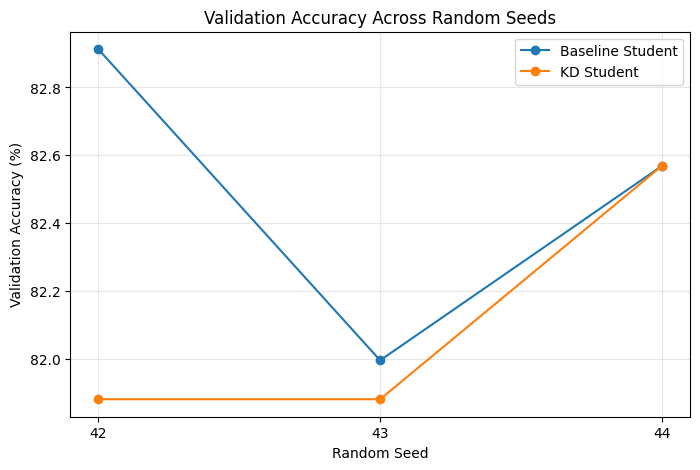

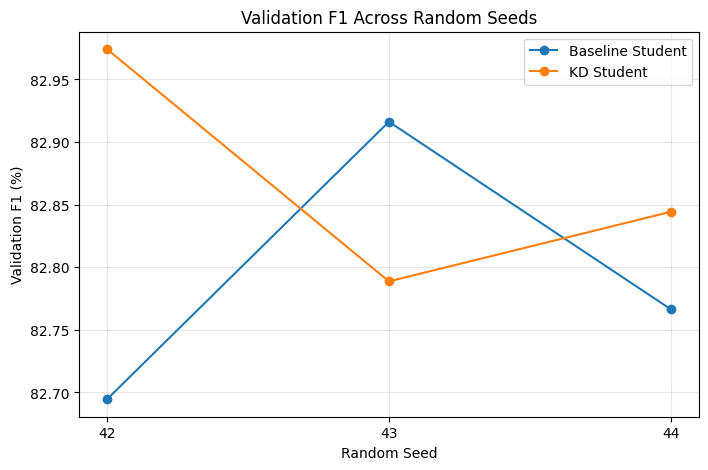


ROBUSTNESS FIGURES SAVED
Accuracy figure: /content/drive/MyDrive/SLM_KD_Research/figures/three_seed_accuracy_robustness.png
F1 figure: /content/drive/MyDrive/SLM_KD_Research/figures/three_seed_f1_robustness.png

Files exist:
True True


In [ ]:
# ============================================
# DAY 4 — FIGURE: 3-SEED ROBUSTNESS
# ============================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

# Load actual saved results
comparison_path = os.path.join(
    RESULTS_DIR,
    "three_seed_comparison.csv"
)

df = pd.read_csv(comparison_path)

print("Loaded data:")
print(df)

# ============================================
# ACCURACY
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["seed"],
    df["baseline_accuracy"] * 100,
    marker="o",
    label="Baseline Student"
)

plt.plot(
    df["seed"],
    df["kd_accuracy"] * 100,
    marker="o",
    label="KD Student"
)

plt.xlabel("Random Seed")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Across Random Seeds")
plt.xticks(df["seed"])
plt.legend()
plt.grid(True, alpha=0.3)

accuracy_path = os.path.join(
    FIGURES_DIR,
    "three_seed_accuracy_robustness.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================
# F1
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["seed"],
    df["baseline_f1"] * 100,
    marker="o",
    label="Baseline Student"
)

plt.plot(
    df["seed"],
    df["kd_f1"] * 100,
    marker="o",
    label="KD Student"
)

plt.xlabel("Random Seed")
plt.ylabel("Validation F1 (%)")
plt.title("Validation F1 Across Random Seeds")
plt.xticks(df["seed"])
plt.legend()
plt.grid(True, alpha=0.3)

f1_path = os.path.join(
    FIGURES_DIR,
    "three_seed_f1_robustness.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================
# VERIFY
# ============================================

print("\n====================================")
print("ROBUSTNESS FIGURES SAVED")
print("====================================")

print(
    "Accuracy figure:",
    accuracy_path
)

print(
    "F1 figure:",
    f1_path
)

print("\nFiles exist:")
print(
    os.path.exists(accuracy_path),
    os.path.exists(f1_path)
)

In [ ]:
import pandas as pd
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

inference_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "inference_results.csv"
)

df = pd.read_csv(inference_path)

print("====================================")
print("ACTUAL COLUMN NAMES")
print("====================================")

print(df.columns.tolist())

print("\n====================================")
print("ACTUAL DATA")
print("====================================")

print(df)

ACTUAL COLUMN NAMES
['experiment', 'model', 'hardware', 'batch_size', 'warmup_runs', 'measured_runs', 'average_latency_ms', 'throughput_samples_per_sec', 'peak_gpu_memory_mb_after_reset']

ACTUAL DATA
            experiment             model  hardware  batch_size  warmup_runs  \
0  E1_baseline_student  Baseline Student  Tesla T4          16           10   
1        E2_KD_student        KD Student  Tesla T4          16           10   

   measured_runs  average_latency_ms  throughput_samples_per_sec  \
0             50             2.58079                 6199.645731   
1             50             3.18771                 5019.283182   

   peak_gpu_memory_mb_after_reset  
0                           29.34  
1                           29.34  


MASTER RESULTS:
            experiment                               model  parameters  \
0           E0_teacher  textattack/bert-base-uncased-SST-2   109483778   
1  E1_baseline_student   google/bert_uncased_L-2_H-128_A-2     4386178   
2        E2_KD_student   google/bert_uncased_L-2_H-128_A-2     4386178   

   validation_accuracy  validation_f1  
0             0.924312       0.926339  
1             0.829128       0.826945  
2             0.818807       0.829741  

INFERENCE RESULTS:
            experiment             model  hardware  batch_size  warmup_runs  \
0  E1_baseline_student  Baseline Student  Tesla T4          16           10   
1        E2_KD_student        KD Student  Tesla T4          16           10   

   measured_runs  average_latency_ms  throughput_samples_per_sec  \
0             50             2.58079                 6199.645731   
1             50             3.18771                 5019.283182   

   peak_gpu_memory_mb_after_reset  
0                           

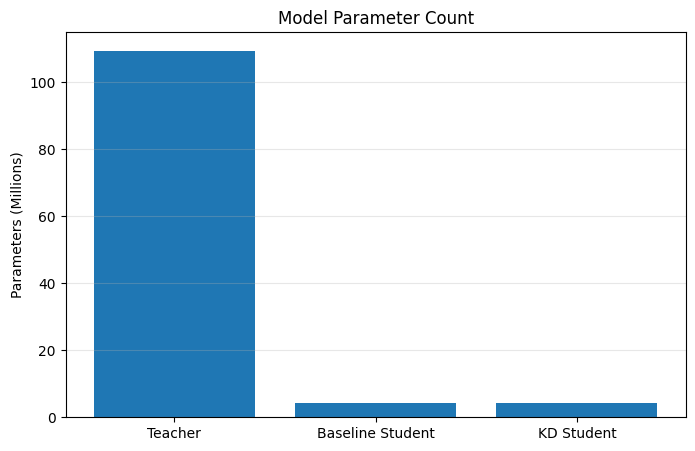

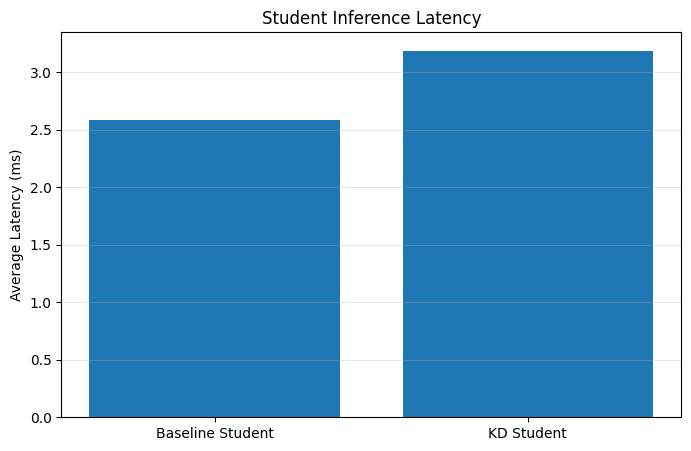

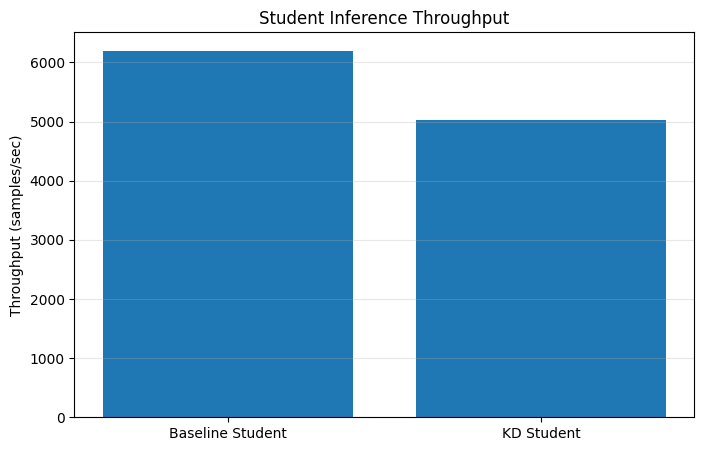


EFFICIENCY FIGURES SAVED
Parameter: /content/drive/MyDrive/SLM_KD_Research/figures/parameter_count_comparison.png
Latency: /content/drive/MyDrive/SLM_KD_Research/figures/inference_latency_comparison.png
Throughput: /content/drive/MyDrive/SLM_KD_Research/figures/inference_throughput_comparison.png

Files exist:
Parameter: True
Latency: True
Throughput: True


In [ ]:
# ============================================
# STEP 12 — RESOURCE EFFICIENCY FIGURES
# CORRECTED VERSION
# ============================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

# ============================================
# LOAD ACTUAL RESULTS
# ============================================

master_path = os.path.join(
    RESULTS_DIR,
    "master_results.csv"
)

inference_path = os.path.join(
    RESULTS_DIR,
    "inference_results.csv"
)

master = pd.read_csv(master_path)
inference = pd.read_csv(inference_path)

print("MASTER RESULTS:")
print(master)

print("\nINFERENCE RESULTS:")
print(inference)

# ============================================
# FIGURE 1 — PARAMETER COUNT
# ============================================

labels = [
    "Teacher",
    "Baseline Student",
    "KD Student"
]

parameters_millions = [
    109483778 / 1_000_000,
    4386178 / 1_000_000,
    4386178 / 1_000_000
]

plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    parameters_millions
)

plt.ylabel("Parameters (Millions)")
plt.title("Model Parameter Count")
plt.grid(axis="y", alpha=0.3)

parameter_path = os.path.join(
    FIGURES_DIR,
    "parameter_count_comparison.png"
)

plt.savefig(
    parameter_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================
# FIGURE 2 — INFERENCE LATENCY
# ============================================

plt.figure(figsize=(8, 5))

plt.bar(
    inference["model"],
    inference["average_latency_ms"]
)

plt.ylabel("Average Latency (ms)")
plt.title("Student Inference Latency")
plt.grid(axis="y", alpha=0.3)

latency_path = os.path.join(
    FIGURES_DIR,
    "inference_latency_comparison.png"
)

plt.savefig(
    latency_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================
# FIGURE 3 — THROUGHPUT
# ============================================

plt.figure(figsize=(8, 5))

plt.bar(
    inference["model"],
    inference["throughput_samples_per_sec"]
)

plt.ylabel("Throughput (samples/sec)")
plt.title("Student Inference Throughput")
plt.grid(axis="y", alpha=0.3)

throughput_path = os.path.join(
    FIGURES_DIR,
    "inference_throughput_comparison.png"
)

plt.savefig(
    throughput_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================
# VERIFY
# ============================================

print("\n====================================")
print("EFFICIENCY FIGURES SAVED")
print("====================================")

print("Parameter:", parameter_path)
print("Latency:", latency_path)
print("Throughput:", throughput_path)

print("\nFiles exist:")

print(
    "Parameter:",
    os.path.exists(parameter_path)
)

print(
    "Latency:",
    os.path.exists(latency_path)
)

print(
    "Throughput:",
    os.path.exists(throughput_path)
)

In [ ]:
# ============================================
# STEP 13 — FINAL RESULTS TABLE
# ============================================

import os
import pandas as pd
import numpy as np

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

# ============================================
# LOAD EXISTING RESULTS
# ============================================

master = pd.read_csv(
    os.path.join(RESULTS_DIR, "master_results.csv")
)

inference = pd.read_csv(
    os.path.join(RESULTS_DIR, "inference_results.csv")
)

three_seed = pd.read_csv(
    os.path.join(RESULTS_DIR, "three_seed_comparison.csv")
)

# ============================================
# CALCULATE 3-SEED MEAN ± SD
# ============================================

baseline_acc_mean = three_seed["baseline_accuracy"].mean()
baseline_acc_sd = three_seed["baseline_accuracy"].std(ddof=1)

kd_acc_mean = three_seed["kd_accuracy"].mean()
kd_acc_sd = three_seed["kd_accuracy"].std(ddof=1)

baseline_f1_mean = three_seed["baseline_f1"].mean()
baseline_f1_sd = three_seed["baseline_f1"].std(ddof=1)

kd_f1_mean = three_seed["kd_f1"].mean()
kd_f1_sd = three_seed["kd_f1"].std(ddof=1)

# ============================================
# GET PARAMETER COUNTS
# ============================================

teacher_params = int(
    master.loc[
        master["experiment"] == "E0_teacher",
        "parameters"
    ].iloc[0]
)

baseline_params = int(
    master.loc[
        master["experiment"] == "E1_baseline_student",
        "parameters"
    ].iloc[0]
)

kd_params = int(
    master.loc[
        master["experiment"] == "E2_KD_student",
        "parameters"
    ].iloc[0]
)

# ============================================
# GET INFERENCE RESULTS
# ============================================

baseline_inf = inference[
    inference["experiment"] == "E1_baseline_student"
].iloc[0]

kd_inf = inference[
    inference["experiment"] == "E2_KD_student"
].iloc[0]

# ============================================
# CREATE FINAL TABLE
# ============================================

final_table = pd.DataFrame([
    {
        "Experiment": "E0 Teacher",
        "Model": "BERT-base SST-2",
        "Parameters_M": teacher_params / 1_000_000,
        "Validation_Accuracy": master.loc[
            master["experiment"] == "E0_teacher",
            "validation_accuracy"
        ].iloc[0] * 100,
        "Validation_F1": master.loc[
            master["experiment"] == "E0_teacher",
            "validation_f1"
        ].iloc[0] * 100,
        "3Seed_Accuracy_Mean": np.nan,
        "3Seed_Accuracy_SD": np.nan,
        "3Seed_F1_Mean": np.nan,
        "3Seed_F1_SD": np.nan,
        "Latency_ms": np.nan,
        "Throughput_samples_sec": np.nan
    },
    {
        "Experiment": "E1 Baseline Student",
        "Model": "BERT-Tiny",
        "Parameters_M": baseline_params / 1_000_000,
        "Validation_Accuracy": master.loc[
            master["experiment"] == "E1_baseline_student",
            "validation_accuracy"
        ].iloc[0] * 100,
        "Validation_F1": master.loc[
            master["experiment"] == "E1_baseline_student",
            "validation_f1"
        ].iloc[0] * 100,
        "3Seed_Accuracy_Mean": baseline_acc_mean * 100,
        "3Seed_Accuracy_SD": baseline_acc_sd * 100,
        "3Seed_F1_Mean": baseline_f1_mean * 100,
        "3Seed_F1_SD": baseline_f1_sd * 100,
        "Latency_ms": baseline_inf["average_latency_ms"],
        "Throughput_samples_sec": baseline_inf[
            "throughput_samples_per_sec"
        ]
    },
    {
        "Experiment": "E2 KD Student",
        "Model": "BERT-Tiny + KD",
        "Parameters_M": kd_params / 1_000_000,
        "Validation_Accuracy": master.loc[
            master["experiment"] == "E2_KD_student",
            "validation_accuracy"
        ].iloc[0] * 100,
        "Validation_F1": master.loc[
            master["experiment"] == "E2_KD_student",
            "validation_f1"
        ].iloc[0] * 100,
        "3Seed_Accuracy_Mean": kd_acc_mean * 100,
        "3Seed_Accuracy_SD": kd_acc_sd * 100,
        "3Seed_F1_Mean": kd_f1_mean * 100,
        "3Seed_F1_SD": kd_f1_sd * 100,
        "Latency_ms": kd_inf["average_latency_ms"],
        "Throughput_samples_sec": kd_inf[
            "throughput_samples_per_sec"
        ]
    }
])

# ============================================
# SAVE CSV
# ============================================

final_path = os.path.join(
    RESULTS_DIR,
    "final_results_table.csv"
)

final_table.to_csv(
    final_path,
    index=False
)

# ============================================
# DISPLAY
# ============================================

print("====================================")
print("FINAL RESULTS TABLE")
print("====================================")

display(
    final_table.round(4)
)

print("\n====================================")
print("SAVED")
print("====================================")

print(final_path)

print(
    "\nFile exists:",
    os.path.exists(final_path)
)

FINAL RESULTS TABLE


,Experiment,Model,Parameters_M,Validation_Accuracy,Validation_F1,3Seed_Accuracy_Mean,3Seed_Accuracy_SD,3Seed_F1_Mean,3Seed_F1_SD,Latency_ms,Throughput_samples_sec
0,E0 Teacher,BERT-base SST-2,109.4838,92.4312,92.6339,NaN,NaN,NaN,NaN,NaN,NaN
1,E1 Baseline Student,BERT-Tiny,4.3862,82.9128,82.6945,82.4924,0.4635,82.7924,0.1131,2.5808,6199.6457
2,E2 KD Student,BERT-Tiny + KD,4.3862,81.8807,82.9741,82.1101,0.3973,82.8690,0.0952,3.1877,5019.2832



SAVED
/content/drive/MyDrive/SLM_KD_Research/results/final_results_table.csv

File exists: True


In [ ]:
# ============================================
# STEP 14 — ERROR ANALYSIS TABLE
# ============================================

import os
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

# Actual counts from saved error analysis
error_table = pd.DataFrame([
    {
        "Category": "Both models correct",
        "Count": 683
    },
    {
        "Category": "Both models wrong",
        "Count": 118
    },
    {
        "Category": "Baseline correct, KD wrong",
        "Count": 40
    },
    {
        "Category": "KD correct, Baseline wrong",
        "Count": 31
    }
])

# Add percentage of validation set
total = 872

error_table["Percentage"] = (
    error_table["Count"] / total * 100
)

# Save
error_path = os.path.join(
    RESULTS_DIR,
    "final_error_analysis_table.csv"
)

error_table.to_csv(
    error_path,
    index=False
)

# Display
print("====================================")
print("FINAL ERROR ANALYSIS")
print("====================================")

display(
    error_table.round(2)
)

print("\n====================================")
print("SAVED")
print("====================================")

print(error_path)

print(
    "File exists:",
    os.path.exists(error_path)
)

FINAL ERROR ANALYSIS


,Category,Count,Percentage
0,Both models correct,683,78.33
1,Both models wrong,118,13.53
2,"Baseline correct, KD wrong",40,4.59
3,"KD correct, Baseline wrong",31,3.56



SAVED
/content/drive/MyDrive/SLM_KD_Research/results/final_error_analysis_table.csv
File exists: True


In [ ]:
# ============================================
# STEP 15 — RESEARCH INTERPRETATION REPORT
# ============================================

import os
import pandas as pd
import numpy as np

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")

os.makedirs(LOGS_DIR, exist_ok=True)

# ============================================
# LOAD ACTUAL SAVED RESULTS
# ============================================

master = pd.read_csv(
    os.path.join(RESULTS_DIR, "master_results.csv")
)

three_seed = pd.read_csv(
    os.path.join(RESULTS_DIR, "three_seed_comparison.csv")
)

inference = pd.read_csv(
    os.path.join(RESULTS_DIR, "inference_results.csv")
)

error = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_error_analysis_table.csv")
)

agreement = pd.read_csv(
    os.path.join(RESULTS_DIR, "teacher_student_agreement.csv")
)

# ============================================
# MAIN RESULTS
# ============================================

teacher = master[
    master["experiment"] == "E0_teacher"
].iloc[0]

baseline = master[
    master["experiment"] == "E1_baseline_student"
].iloc[0]

kd = master[
    master["experiment"] == "E2_KD_student"
].iloc[0]

# ============================================
# CALCULATIONS
# ============================================

accuracy_difference = (
    kd["validation_accuracy"]
    - baseline["validation_accuracy"]
) * 100

f1_difference = (
    kd["validation_f1"]
    - baseline["validation_f1"]
) * 100

parameter_reduction = (
    1 -
    baseline["parameters"] / teacher["parameters"]
) * 100

parameter_ratio = (
    teacher["parameters"] /
    baseline["parameters"]
)

mean_baseline_accuracy = three_seed[
    "baseline_accuracy"
].mean() * 100

mean_kd_accuracy = three_seed[
    "kd_accuracy"
].mean() * 100

mean_baseline_f1 = three_seed[
    "baseline_f1"
].mean() * 100

mean_kd_f1 = three_seed[
    "kd_f1"
].mean() * 100

mean_accuracy_difference = (
    mean_kd_accuracy -
    mean_baseline_accuracy
)

mean_f1_difference = (
    mean_kd_f1 -
    mean_baseline_f1
)

baseline_inf = inference[
    inference["experiment"] == "E1_baseline_student"
].iloc[0]

kd_inf = inference[
    inference["experiment"] == "E2_KD_student"
].iloc[0]

# Agreement values
print("Agreement data:")
print(agreement)

# ============================================
# CREATE INTERPRETATION
# ============================================

report = f"""
# Research Interpretation

## Research Question

Can knowledge distillation improve the task performance of a small
language model compared with conventional fine-tuning, while retaining
its efficiency advantages?

## 1. Main Performance Finding

The teacher model achieved a validation accuracy of
{teacher["validation_accuracy"] * 100:.2f}% and an F1 score of
{teacher["validation_f1"] * 100:.2f}%.

The baseline BERT-Tiny student achieved
{baseline["validation_accuracy"] * 100:.2f}% validation accuracy and
{baseline["validation_f1"] * 100:.2f}% F1.

The KD student achieved
{kd["validation_accuracy"] * 100:.2f}% validation accuracy and
{kd["validation_f1"] * 100:.2f}% F1.

Under the main seed-42 configuration, KD changed accuracy by
{accuracy_difference:+.2f} percentage points and F1 by
{f1_difference:+.2f} percentage points relative to conventional
supervised fine-tuning.

Therefore, the main experiment does not support a claim that KD
unconditionally improves student performance. Instead, the effect is
metric-dependent: F1 increased slightly while accuracy decreased.

## 2. Three-Seed Robustness

Across seeds 42, 43, and 44:

Baseline mean accuracy:
{mean_baseline_accuracy:.2f}% ±
{three_seed["baseline_accuracy"].std(ddof=1) * 100:.2f}

KD mean accuracy:
{mean_kd_accuracy:.2f}% ±
{three_seed["kd_accuracy"].std(ddof=1) * 100:.2f}

Baseline mean F1:
{mean_baseline_f1:.2f}% ±
{three_seed["baseline_f1"].std(ddof=1) * 100:.2f}

KD mean F1:
{mean_kd_f1:.2f}% ±
{three_seed["kd_f1"].std(ddof=1) * 100:.2f}

The mean KD-minus-baseline difference was
{mean_accuracy_difference:+.2f} percentage points for accuracy and
{mean_f1_difference:+.2f} percentage points for F1.

Thus, across the three tested seeds, KD showed a small decrease in mean
accuracy and a small increase in mean F1. Because only three seeds were
tested, these results should be interpreted as robustness evidence
rather than as a basis for strong statistical significance claims.

## 3. Resource Efficiency

The teacher contains approximately
{teacher["parameters"] / 1_000_000:.2f} million parameters.

The student contains approximately
{baseline["parameters"] / 1_000_000:.2f} million parameters.

This corresponds to approximately
{parameter_reduction:.2f}% fewer parameters in the student compared
with the teacher, or approximately {parameter_ratio:.2f} times fewer
parameters.

The baseline and KD students use the same student architecture and
therefore have the same parameter count.

The resource advantage demonstrated by this experiment is therefore
primarily the compact student architecture relative to the teacher,
not a reduction in model size caused by KD.

## 4. Inference Efficiency

On the Tesla T4 benchmark using batch size 16 and 50 measured runs:

Baseline Student:
- Average latency: {baseline_inf["average_latency_ms"]:.2f} ms
- Throughput: {baseline_inf["throughput_samples_per_sec"]:.2f} samples/sec

KD Student:
- Average latency: {kd_inf["average_latency_ms"]:.2f} ms
- Throughput: {kd_inf["throughput_samples_per_sec"]:.2f} samples/sec

Under this specific benchmark protocol, the KD checkpoint had higher
latency and lower throughput than the baseline checkpoint.

Therefore, the experiment does not support a claim that KD itself made
inference more efficient.

## 5. Error Analysis

The validation-set error analysis found:

- Both models correct: 683 examples
- Both models wrong: 118 examples
- Baseline correct, KD wrong: 40 examples
- KD correct, baseline wrong: 31 examples

The two students therefore behaved similarly on most validation
examples, while still showing a non-trivial set of disagreements.

The difference between the two disagreement directions should be
reported descriptively rather than interpreted as evidence of a
general advantage of one method.

## 6. Overall Interpretation

The experiment demonstrates that knowledge distillation can produce a
student model with performance characteristics that differ from
conventional supervised fine-tuning, but the observed effect in this
configuration is mixed rather than uniformly positive.

The KD student showed a small F1 advantage in both the main experiment
and the three-seed mean, while its accuracy was lower than the baseline
in the main experiment and in the three-seed mean.

The student architecture itself provides a substantial parameter
reduction relative to the teacher. However, the inference benchmark
showed no efficiency advantage for the KD checkpoint over the baseline
checkpoint under the tested hardware and measurement protocol.

These findings suggest that the usefulness of knowledge distillation
for this compact student should be evaluated jointly across multiple
task metrics and resource measurements rather than through a single
performance metric.

## 7. Limitations

1. The evaluation is based on the SST-2 validation split because the
   public test split available through the dataset interface did not
   provide usable labels for local accuracy/F1 computation.

2. Only three random seeds were evaluated for robustness.

3. The KD configuration used one temperature and one alpha value
   (T=2.0 and alpha=0.5). No systematic hyperparameter sweep was
   performed.

4. Inference benchmarking was performed on a Tesla T4 using the
   recorded batch-size and warm-up protocol. Results may differ on
   other hardware and deployment configurations.

5. Teacher inference was not included in the recorded latency and
   throughput benchmark, so direct teacher-versus-student inference
   speed claims are not made.

6. The experiment evaluates one task and one dataset, so the findings
   should not automatically be generalized to other NLP tasks.

## 8. Final Research Position

The evidence from the current experiment supports a cautious conclusion:

Knowledge distillation did not produce a uniform performance improvement
over conventional supervised fine-tuning for the BERT-Tiny student under
the tested SST-2 configuration. It produced a small F1 increase but a
small accuracy decrease on average across three seeds. The student
architecture nevertheless achieved a substantial parameter reduction
relative to the teacher.

Further evaluation across additional datasets, KD hyperparameters,
random seeds, and deployment environments would be required before
making broader claims about the general effectiveness of KD for
resource-efficient SLMs.
"""

# ============================================
# SAVE REPORT
# ============================================

report_path = os.path.join(
    LOGS_DIR,
    "research_interpretation.md"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# ============================================
# DISPLAY
# ============================================

print("====================================")
print("RESEARCH INTERPRETATION CREATED")
print("====================================")

print(report)

print("\n====================================")
print("SAVED")
print("====================================")

print(report_path)

print(
    "\nFile exists:",
    os.path.exists(report_path)
)

Agreement data:
            comparison  agreement  agreement_percent
0  Baseline vs Teacher   0.842890          84.288991
1        KD vs Teacher   0.832569          83.256881
2       Baseline vs KD   0.918578          91.857798
RESEARCH INTERPRETATION CREATED

# Research Interpretation

## Research Question

Can knowledge distillation improve the task performance of a small
language model compared with conventional fine-tuning, while retaining
its efficiency advantages?

## 1. Main Performance Finding

The teacher model achieved a validation accuracy of
92.43% and an F1 score of
92.63%.

The baseline BERT-Tiny student achieved
82.91% validation accuracy and
82.69% F1.

The KD student achieved
81.88% validation accuracy and
82.97% F1.

Under the main seed-42 configuration, KD changed accuracy by
-1.03 percentage points and F1 by
+0.28 percentage points relative to conventional
supervised fine-tuning.

Therefore, the main experiment does not support a claim that KD
unconditionally improv

In [ ]:
# ============================================
# FINAL PROJECT SAVE / BACKUP CHECK
# ============================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

print("=" * 60)
print("SLM KD RESEARCH — FINAL SAVE CHECK")
print("=" * 60)

# --------------------------------------------
# 1. PROJECT ROOT
# --------------------------------------------

print("\n[1] PROJECT ROOT")
print("Exists:", os.path.exists(PROJECT_ROOT))
print("Path:", PROJECT_ROOT)

# --------------------------------------------
# 2. IMPORTANT FOLDERS
# --------------------------------------------

folders = [
    "data",
    "models",
    "results",
    "logs",
    "notebooks",
    "figures"
]

print("\n[2] PROJECT FOLDERS")

for folder in folders:
    path = os.path.join(PROJECT_ROOT, folder)
    print(f"{folder:15} -> {os.path.exists(path)}")

# --------------------------------------------
# 3. IMPORTANT RESULT FILES
# --------------------------------------------

important_files = [
    "results/baseline_results.json",
    "results/kd_results.json",
    "results/baseline_training_history.json",
    "results/kd_training_history.json",

    "results/master_results.csv",
    "results/efficiency_results.csv",
    "results/inference_results.csv",
    "results/training_comparison.csv",
    "results/predictions.csv",
    "results/error_analysis.csv",
    "results/teacher_student_agreement.csv",

    "results/three_seed_comparison.csv",
    "results/three_seed_summary.csv",

    "results/final_results_table.csv",
    "results/final_error_analysis_table.csv",

    "logs/Day3_Research_Log.md",
    "logs/research_interpretation.md"
]

print("\n[3] IMPORTANT RESULT / LOG FILES")

missing_files = []

for file in important_files:
    path = os.path.join(PROJECT_ROOT, file)

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"✓ {file:55} {size_kb:8.2f} KB")
    else:
        print(f"✗ MISSING: {file}")
        missing_files.append(file)

# --------------------------------------------
# 4. FIGURES
# --------------------------------------------

figure_files = [
    "figures/performance_accuracy_comparison.png",
    "figures/performance_f1_comparison.png",
    "figures/three_seed_accuracy_robustness.png",
    "figures/three_seed_f1_robustness.png",
    "figures/parameter_count_comparison.png",
    "figures/inference_latency_comparison.png",
    "figures/inference_throughput_comparison.png"
]

print("\n[4] FIGURES")

missing_figures = []

for file in figure_files:
    path = os.path.join(PROJECT_ROOT, file)

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"✓ {file:55} {size_kb:8.2f} KB")
    else:
        print(f"✗ MISSING: {file}")
        missing_figures.append(file)

# --------------------------------------------
# 5. BASELINE CHECKPOINT
# --------------------------------------------

print("\n[5] BASELINE CHECKPOINT")

baseline_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "baseline_student",
    "final"
)

print("Exists:", os.path.exists(baseline_path))

# --------------------------------------------
# 6. KD CHECKPOINT
# --------------------------------------------

print("\n[6] KD CHECKPOINT")

kd_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "kd",
    "student_epoch3"
)

print("Exists:", os.path.exists(kd_path))

# --------------------------------------------
# 7. SEED CHECKPOINTS
# --------------------------------------------

seed_checkpoints = [
    "models/baseline_student_seed43",
    "models/kd/student_seed43_epoch3",
    "models/baseline_student_seed44",
    "models/kd/student_seed44_epoch3"
]

print("\n[7] ROBUSTNESS CHECKPOINTS")

for checkpoint in seed_checkpoints:
    path = os.path.join(PROJECT_ROOT, checkpoint)
    print(f"{checkpoint:45} -> {os.path.exists(path)}")

# --------------------------------------------
# 8. TOTAL FILE COUNT
# --------------------------------------------

print("\n[8] PROJECT FILE COUNT")

total_files = 0

for root, dirs, files in os.walk(PROJECT_ROOT):
    total_files += len(files)

print("Total files in project:", total_files)

# --------------------------------------------
# 9. FINAL VERDICT
# --------------------------------------------

print("\n" + "=" * 60)
print("FINAL VERDICT")
print("=" * 60)

if os.path.exists(PROJECT_ROOT) and not missing_files and not missing_figures:
    print("✅ ALL IMPORTANT PROJECT FILES ARE SAVED IN GOOGLE DRIVE.")
    print("✅ RESULTS ARE SAFE TO KEEP.")
    print("✅ YOU CAN DISCONNECT THE COLAB RUNTIME.")
else:
    print("⚠️ SOME FILES ARE MISSING.")
    print("\nMissing result/log files:")
    for f in missing_files:
        print(" -", f)

    print("\nMissing figures:")
    for f in missing_figures:
        print(" -", f)

print("\nProject location:")
print(PROJECT_ROOT)

SLM KD RESEARCH — FINAL SAVE CHECK

[1] PROJECT ROOT
Exists: True
Path: /content/drive/MyDrive/SLM_KD_Research

[2] PROJECT FOLDERS
data            -> True
models          -> True
results         -> True
logs            -> True
notebooks       -> True
figures         -> True

[3] IMPORTANT RESULT / LOG FILES
✓ results/baseline_results.json                               0.44 KB
✓ results/kd_results.json                                     0.54 KB
✓ results/baseline_training_history.json                      0.59 KB
✓ results/kd_training_history.json                            0.58 KB
✓ results/master_results.csv                                  0.34 KB
✓ results/efficiency_results.csv                              0.17 KB
✓ results/inference_results.csv                               0.32 KB
✓ results/training_comparison.csv                             0.50 KB
✓ results/predictions.csv                                   115.30 KB
✓ results/error_analysis.csv                                